# Compare SVM65 and Whisper fusion

Use the same 40,000 clips and speaker splits as `E1_acoustic_91_feature_count_comparison.ipynb`.

- **SVM65:** Use E1's selected 65 features and SVM settings.
- **Fusion SVM:** Add Whisper embeddings to the same 65 features.

Use raw SVM scores with threshold zero. **Run All includes test evaluation.**
The completed 40k E1 run selected 65 SVM features by validation balanced accuracy
(97.12%, versus 96.81% for all 91 features). Its saved SVM65 scored 96.69% on
the 6,119 test clips, versus 96.53% for SVM91. Keep this validation-selected
feature count for fusion; the test results are a reference, not a tuning target.


## 1. Settings

Run from the project folder. For Colab, set `USE_GOOGLE_DRIVE=True`.
Run the E1 91-feature comparison first. It saves the splits, feature cache,
and `results_91/svm_65.joblib` in `outputs/e1_feature_study_accent_40000/`.

Keep the source audio in `data/*_subset/part-*.parquet` and `scripts/cv_utils.py`.
Whisper downloads its public weights anonymously and uses the GPU when available.
No Hugging Face login is needed; stored tokens are ignored for these downloads.
Set `REBUILD_FEATURES=True` to rebuild Whisper embeddings.
Save this comparison in `outputs/svm65_fusion_comparison_40000/`.
The acoustic model, feature columns, cache and speaker splits must all match
the completed 40k E1 study. The first run prepares Whisper embeddings for
40,000 clips; existing 30k embeddings and results remain in their original folder.


In [1]:
# Install these packages if necessary. Then restart the kernel.
# %pip -q install "transformers>=4.56,<5" torch librosa numpy pandas pyarrow soundfile soxr scikit-learn matplotlib joblib

from pathlib import Path
import sys
USE_GOOGLE_DRIVE = False
if USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_ROOT = Path('/content/drive/MyDrive/Singlish')
else:
    PROJECT_ROOT = Path.cwd()

PROJECT_ROOT = PROJECT_ROOT.resolve()
sys.path.insert(0, str(PROJECT_ROOT))
DATA_ROOT = PROJECT_ROOT / 'data'
OUTPUT_DIR = PROJECT_ROOT / 'outputs' / 'svm65_fusion_comparison_40000'
CACHE_DIR = OUTPUT_DIR / 'feature_cache'
CHART_DIR = OUTPUT_DIR / 'charts'
E1_DIR = PROJECT_ROOT / 'outputs' / 'e1_feature_study_accent_40000'
E1_MODEL_PATH = E1_DIR / 'results_91' / 'svm_65.joblib'
E1_STUDY_PATH = E1_DIR / 'results_91' / 'study_results.joblib'
for folder in (OUTPUT_DIR, CACHE_DIR, CHART_DIR):
    folder.mkdir(parents=True, exist_ok=True)

EXPECTED_CLIPS = 40_000
EXPECTED_CLASS_COUNTS = {0: 20_000, 1: 20_000}
ACOUSTIC_FEATURE_COUNT = 65

RANDOM_SEED = 42
REBUILD_FEATURES = False
WHISPER_MODEL = 'openai/whisper-base.en'
WHISPER_REVISION = 'main'  # Use a commit hash to select a fixed version of the weights.
WHISPER_BATCH_SIZE = 64
DECODE_WORKERS = 8
PCA_DIMENSIONS = 32
FUSION_C_VALUES = [0.01, 0.1, 1.0, 10.0]
CV_FOLDS = 3
BOOTSTRAP_REPEATS = 2000
RUN_SPEAKER_FOLDS = True
print('Upstream audio:', DATA_ROOT)
print('New results:', OUTPUT_DIR)

Upstream audio: /home/mh/E1_Feature_EngineeringV2/data
New results: /home/mh/E1_Feature_EngineeringV2/outputs/svm65_fusion_comparison_40000


In [2]:
import hashlib
import json
from concurrent.futures import ThreadPoolExecutor
from time import perf_counter
import joblib
import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.metrics import (balanced_accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
    f1_score, roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from scripts.cv_utils import load_accent_data, decode_flac

META_COLUMNS = ['label', 'speaker_group', 'split', 'source', 'source_clip_id',
                'speaker_id', 'accent_group', 'sampling_rate']


def digest(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True).encode()).hexdigest()


def file_hash(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def write_json(path, value):
    temporary = path.with_name(path.name + '.tmp')
    temporary.write_text(json.dumps(value, indent=2, sort_keys=True) + '\n')
    temporary.replace(path)


def whisper_features(clips, cache_dir, *, model_name, revision, batch_size, workers, rebuild):
    # Reuse embeddings only for matching audio and settings.
    settings = {
        'dataset_id': dataset_id, 'audio_id': audio_id,
        'model': model_name, 'revision': revision,
        'pooling': 'mean_valid_encoder_frames_v1', 'sample_rate': 16000,
    }
    cache_id = digest(settings)
    cache_path = cache_dir / f'whisper_{cache_id}.npz'
    if cache_path.exists() and not rebuild:
        with np.load(cache_path, allow_pickle=False) as cache:
            if str(cache['cache_id'].item()) != cache_id:
                raise ValueError('Whisper cache identity differs.')
            for key, expected in [('clip_ids', clip_ids), ('labels', labels), ('groups', groups)]:
                if not np.array_equal(cache[key], expected):
                    raise ValueError(f'Whisper cache {key} differ.')
            features = cache['features'].copy()
            provenance = json.loads(str(cache['provenance_json'].item()))
        if features.ndim != 2 or features.shape[0] != len(clips) or features.shape[1] < 2 or not np.isfinite(features).all():
            raise ValueError('Invalid Whisper embeddings.')
        print('Loaded Whisper cache:', cache_path)
        return features, provenance

    import torch
    import transformers
    from transformers import WhisperFeatureExtractor, WhisperModel

    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    # Whisper is public; ignore stored credentials, which may be expired.
    extractor = WhisperFeatureExtractor.from_pretrained(model_name, revision=revision, token=False)
    whisper = WhisperModel.from_pretrained(model_name, revision=revision, token=False).to(device).eval()
    encoder = whisper.get_encoder()
    effective_batch = batch_size if device.type == 'cuda' else min(batch_size, 4)
    features = np.empty((len(clips), whisper.config.d_model), dtype=np.float32)
    started = perf_counter()
    print('Whisper device:', device, '| batch size:', effective_batch, flush=True)
    with ThreadPoolExecutor(max_workers=workers) as pool, torch.inference_mode():
        for first in range(0, len(clips), effective_batch):
            audio = list(pool.map(decode_flac, clips['audio_flac'].iloc[first:first + effective_batch]))
            for waveform in audio:
                if waveform.ndim != 1 or not np.isfinite(waveform).all() or not 3 <= len(waveform) / 16000 <= 6:
                    raise ValueError('Expected finite mono audio lasting 3–6 seconds.')
            # Whisper pads its mel inputs; pool only the clip's frames.
            batch = extractor(audio, sampling_rate=16000, return_tensors='pt')
            hidden = encoder(batch.input_features.to(device)).last_hidden_state
            lengths = torch.tensor([(len(waveform) + 2 * extractor.hop_length - 1)
                                    // (2 * extractor.hop_length) for waveform in audio], device=device)
            valid = torch.arange(hidden.shape[1], device=device)[None, :] < lengths[:, None]
            pooled = (hidden * valid.unsqueeze(-1)).sum(dim=1) / valid.sum(dim=1, keepdim=True)
            features[first:first + len(audio)] = pooled.float().cpu().numpy()
            if first == 0 or (first // effective_batch + 1) % 25 == 0 or first + len(audio) == len(clips):
                print(f'Whisper clips: {first + len(audio)}/{len(clips)}', flush=True)
    if not np.isfinite(features).all():
        raise ValueError('Nonfinite Whisper embeddings.')
    provenance = {**settings, 'cache_id': cache_id,
                  'resolved_revision': getattr(whisper.config, '_commit_hash', None),
                  'width': features.shape[1], 'seconds': perf_counter() - started,
                  'torch_version': torch.__version__, 'transformers_version': transformers.__version__}
    temporary = cache_path.with_suffix('.tmp.npz')
    np.savez_compressed(temporary, features=features, clip_ids=clip_ids, labels=labels, groups=groups,
                        cache_id=np.asarray(cache_id), provenance_json=np.asarray(json.dumps(provenance)))
    temporary.replace(cache_path)
    del encoder, whisper
    if device.type == 'cuda':
        torch.cuda.empty_cache()
    return features, provenance

MODEL_NAMES = ('SVM65', 'Fusion SVM')
COLORS = {'SVM65': '#3274a1', 'Fusion SVM': '#e1812c'}

def save_chart(fig, name):
    fig.tight_layout()
    fig.savefig(CHART_DIR / name, dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)

def model_bars(table, category, metric, title, order=None):
    values = table.pivot(index=category, columns='model', values=metric)
    values = values.reindex(table[category].drop_duplicates() if order is None else order)
    fig, ax = plt.subplots(figsize=(10, 4))
    x = np.arange(len(values))
    for offset, name in zip([-0.18, 0.18], MODEL_NAMES):
        bars = ax.bar(x + offset, 100 * values[name], 0.36, label=name, color=COLORS[name])
        ax.bar_label(bars, fmt='%.2f', padding=3, fontsize=8)
    ax.set(xticks=x, xticklabels=values.index, ylim=(0, 104), title=title,
           ylabel=metric.replace('_', ' ').capitalize() + ' (%)')
    ax.legend(loc='lower right')
    return fig, ax

print('numpy:', np.__version__, '| librosa:', librosa.__version__, '| sklearn:', sklearn.__version__)

numpy: 2.5.3 | librosa: 1.0.0 | sklearn: 1.9.1


## 2. Load E1's dataset and splits

Load all 40,000 source clips and keep their speaker splits.
Match E1's saved metadata and audio hashes before preparing features.
Require 20,000 clips per class, including 7,500 MNSC PART1 and 12,500 PART2
clips. Preserve the expanded dataset's assignments for every speaker.


In [3]:
clips = load_accent_data(data_dir=DATA_ROOT, decode_audio=False)
required = ['source', 'clip_id', 'speaker_id', 'split', 'is_singaporean', 'accent_group', 'sampling_rate', 'audio_flac']
if clips[required].isna().any().any() or clips.duplicated(['source', 'clip_id']).any():
    raise ValueError('Missing metadata or duplicate clips.')
if not set(clips['split']) <= {'train', 'val', 'test'}:
    raise ValueError('Expected source train/val/test splits.')
if not clips['is_singaporean'].equals(clips['accent_group'].eq('Singaporean')):
    raise ValueError('Accent groups and labels differ.')
if not clips['sampling_rate'].eq(16000).all():
    raise ValueError('Expected 16 kHz source audio.')
if len(clips) != EXPECTED_CLIPS:
    raise ValueError(f'Expected {EXPECTED_CLIPS:,} clips; found {len(clips):,}. Check DATA_ROOT.')
class_counts = clips['is_singaporean'].astype(np.int64).value_counts().to_dict()
if class_counts != EXPECTED_CLASS_COUNTS:
    raise ValueError(f'Expected class counts {EXPECTED_CLASS_COUNTS}; found {class_counts}.')
mnsc_parts = clips.loc[clips['source'].eq('mnsc'), 'accent_raw'].value_counts().to_dict()
expected_parts = {'Singaporean (MNSC PART1)': 7_500, 'Singaporean (MNSC PART2)': 12_500}
if mnsc_parts != expected_parts:
    raise ValueError(f'Expected MNSC part counts {expected_parts}; found {mnsc_parts}.')
clips = clips.rename(columns={'clip_id': 'source_clip_id'})
clips['clip_id'] = clips['source'] + '::' + clips['source_clip_id']
clips['speaker_group'] = clips['source'] + '::' + clips['speaker_id']
clips['label'] = clips['is_singaporean'].astype(np.int64)
clips['sampling_rate'] = clips['sampling_rate'].astype(np.int64)
clips['split'] = clips['split'].replace({'val': 'validation'})
clips = clips.set_index('clip_id').sort_index()
if not clips.index.is_unique or clips['speaker_id'].str.len().eq(0).any():
    raise ValueError('Invalid clip or speaker IDs.')
if (clips.groupby('speaker_group')['split'].nunique() > 1).any():
    raise ValueError('Speaker overlap between splits.')
if (clips.groupby('speaker_group')['label'].nunique() > 1).any():
    raise ValueError('A speaker has mixed labels.')
if not clips.loc[clips['label'].eq(1), 'source'].eq('mnsc').all():
    raise ValueError('Expected only MNSC positives, as in E1.')

snapshot = clips[META_COLUMNS]
e1_snapshot = pd.read_csv(E1_DIR / 'speaker_splits.csv', index_col='clip_id', keep_default_na=False,
    dtype={column: str for column in ['clip_id', 'speaker_group', 'split', 'source',
                                     'source_clip_id', 'speaker_id', 'accent_group']})
if not snapshot.equals(e1_snapshot):
    raise ValueError('Dataset or splits differ from E1. Run the E1 comparison first.')
dataset_id = digest(snapshot.reset_index().to_dict(orient='records'))
base_metadata = json.loads((E1_DIR / 'current_cache_metadata.json').read_text())
if base_metadata['dataset_id'] != dataset_id:
    raise ValueError('E1 cache dataset differs.')
audio_manifest = [{'clip_id': row.Index, 'sampling_rate': int(row.sampling_rate),
                   'sha256': hashlib.sha256(row.audio_flac).hexdigest()} for row in clips.itertuples()]
if audio_manifest != base_metadata['audio']:
    raise ValueError('Source audio differs from E1.')
audio_id = digest(audio_manifest)

clip_ids = clips.index.to_numpy(dtype=str)
labels = clips['label'].to_numpy(dtype=np.int64)
groups = clips['speaker_group'].to_numpy(dtype=str)
split_names = clips['split'].to_numpy()
train_idx = np.flatnonzero(split_names == 'train')
val_idx = np.flatnonzero(split_names == 'validation')
test_idx = np.flatnonzero(split_names == 'test')
for rows in (train_idx, val_idx, test_idx):
    if set(labels[rows]) != {0, 1}:
        raise ValueError('Both labels must occur in every split.')
development_idx = np.concatenate([train_idx, val_idx])
identity_path = OUTPUT_DIR / 'dataset_identity.json'
identity = {'dataset_id': dataset_id, 'audio_id': audio_id}
if identity_path.exists() and json.loads(identity_path.read_text()) != identity:
    raise ValueError('Dataset changed. Use a new OUTPUT_DIR.')
write_json(identity_path, identity)
snapshot.to_csv(OUTPUT_DIR / 'speaker_splits.csv')
print('Main clips:', len(clips), '| speaker overlap: 0')
split_summary = clips.groupby(['split', 'label']).agg(clips=('label', 'size'), speakers=('speaker_group', 'nunique'))
display(split_summary)

Main clips: 40000 | speaker overlap: 0


clips  speakers
split      label                 
test       0       3085      1267
           1       3034       215
train      0      13848      5960
           1      13949       979
validation 0       3067      1300
           1       3017       204

## 3. Load E1 features and prepare Whisper embeddings

Use E1's saved 91-feature cache and the columns in `results_91/svm_65.joblib`.
Reuse Whisper embeddings only when the dataset, audio, and settings match.
Otherwise extract new embeddings from the source audio.
Confirm that `results_91/study_results.joblib` selected 65 SVM features and
that its dataset and cache identities match the saved model.


In [4]:
feature_started = perf_counter()
with np.load(E1_DIR / 'acoustic_features_91.npz', allow_pickle=False) as cache:
    X91 = cache['features'].copy()
    feature_names = cache['feature_names'].tolist()
    acoustic_cache_id = str(cache['cache_id'].item())
    for key, expected in [('clip_ids', clip_ids), ('labels', labels), ('groups', groups)]:
        if not np.array_equal(cache[key], expected):
            raise ValueError(f'E1 cache {key} differ from the dataset.')
base_cache_id = digest(base_metadata)
expected_cache_id = digest({'base_cache_id': base_cache_id, 'clip_ids': clip_ids.tolist(),
                            'delta_width': 9, 'delta_version': 1})
if acoustic_cache_id != expected_cache_id or X91.shape != (len(clips), 91) or not np.isfinite(X91).all():
    raise ValueError('Invalid E1 acoustic cache.')
e1_model_hash = file_hash(E1_MODEL_PATH)
e1_saved = joblib.load(E1_MODEL_PATH)
if (e1_saved['dataset_id'] != dataset_id or e1_saved['cache_id'] != acoustic_cache_id
        or e1_saved['base_cache_id'] != base_cache_id):
    raise ValueError('E1 SVM65 does not match the cache or dataset.')
e1_study_hash = file_hash(E1_STUDY_PATH)
e1_study = joblib.load(E1_STUDY_PATH)
if (e1_study['dataset_id'] != dataset_id or e1_study['cache_id'] != acoustic_cache_id
        or e1_study['base_cache_id'] != base_cache_id):
    raise ValueError('E1 study results do not match the cache or dataset.')
if e1_study['selected_counts']['svm'] != ACOUSTIC_FEATURE_COUNT:
    raise ValueError('E1 selected a different SVM feature count. Update this comparison to match the study.')
e1_test_rows = [row for row in e1_study['test_scores']
                if row['model'] == 'svm' and row['role'] == 'Validation-selected count'
                and row['feature_count'] == ACOUSTIC_FEATURE_COUNT]
if len(e1_test_rows) != 1:
    raise ValueError('Expected one completed E1 test result for the selected SVM.')
e1_test_reference = e1_test_rows[0]
selected_columns = e1_saved['columns']
if (len(selected_columns) != ACOUSTIC_FEATURE_COUNT or len(set(selected_columns)) != ACOUSTIC_FEATURE_COUNT
        or any(type(i) is not int or not 0 <= i < 91 for i in selected_columns)):
    raise ValueError('Invalid SVM65 feature columns.')
ACOUSTIC_NAMES = e1_saved['feature_names']
if ACOUSTIC_NAMES != [feature_names[i] for i in selected_columns]:
    raise ValueError('SVM65 feature order differs.')
if e1_saved['model'].n_features_in_ != ACOUSTIC_FEATURE_COUNT:
    raise ValueError('E1 model input width differs from its selected feature count.')
if list(e1_saved['model'].classes_) != [0, 1]:
    raise ValueError('Expected Singapore as class 1.')
A = X91[:, selected_columns].astype(np.float32)
acoustic_provenance = {
    'cache': str((E1_DIR / 'acoustic_features_91.npz').relative_to(PROJECT_ROOT)),
    'cache_id': acoustic_cache_id, 'dataset_id': dataset_id,
    'source_model': str(E1_MODEL_PATH.relative_to(PROJECT_ROOT)), 'source_sha256': e1_model_hash,
    'feature_columns': selected_columns, 'feature_names': ACOUSTIC_NAMES,
    'study_results': str(E1_STUDY_PATH.relative_to(PROJECT_ROOT)),
    'study_results_sha256': e1_study_hash, 'selected_feature_count': ACOUSTIC_FEATURE_COUNT,
    'e1_test_reference': e1_test_reference,
}
W, whisper_provenance = whisper_features(clips, CACHE_DIR,
    model_name=WHISPER_MODEL, revision=WHISPER_REVISION, batch_size=WHISPER_BATCH_SIZE,
    workers=DECODE_WORKERS, rebuild=REBUILD_FEATURES)
assert A.shape == (len(clips), ACOUSTIC_FEATURE_COUNT) and W.shape[0] == len(clips)
assert np.isfinite(A).all() and np.isfinite(W).all()
inputs = {'SVM65': A, 'Fusion SVM': np.column_stack((A, W))}
del X91
feature_seconds = perf_counter() - feature_started
write_json(OUTPUT_DIR / 'feature_provenance.json',
    {'acoustic': acoustic_provenance, 'whisper': whisper_provenance,
     'feature_preparation_seconds': feature_seconds})
display(pd.DataFrame({'position': np.arange(1, 66), 'E1_column': selected_columns, 'feature': ACOUSTIC_NAMES}))
print('Acoustic:', A.shape, '| Whisper:', W.shape, '| preparation seconds:', round(feature_seconds, 2))

/home/mh/miniconda3/envs/Singlish314/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Whisper device: cuda | batch size: 64
Whisper clips: 64/40000
Whisper clips: 1600/40000
Whisper clips: 3200/40000
Whisper clips: 4800/40000
Whisper clips: 6400/40000
Whisper clips: 8000/40000
Whisper clips: 9600/40000
Whisper clips: 11200/40000
Whisper clips: 12800/40000
Whisper clips: 14400/40000
Whisper clips: 16000/40000
Whisper clips: 17600/40000
Whisper clips: 19200/40000
Whisper clips: 20800/40000
Whisper clips: 22400/40000
Whisper clips: 24000/40000
Whisper clips: 25600/40000
Whisper clips: 27200/40000
Whisper clips: 28800/40000
Whisper clips: 30400/40000
Whisper clips: 32000/40000
Whisper clips: 33600/40000
Whisper clips: 35200/40000
Whisper clips: 36800/40000
Whisper clips: 38400/40000
Whisper clips: 40000/40000


,position,E1_column,feature
0,1,35,zcr_mean
1,2,14,mfcc_2_std
2,3,31,spectral_bandwidth_mean
3,4,33,spectral_rolloff_mean
4,5,78,mfcc_delta_delta_1_std
...,...,...,...
60,61,72,mfcc_delta_delta_8_mean
61,62,73,mfcc_delta_delta_9_mean
62,63,61,mfcc_delta_10_std
63,64,23,mfcc_11_std


Acoustic: (40000, 65) | Whisper: (40000, 512) | preparation seconds: 410.07


## 4. Define the models

Clone E1's SVM65 settings for training and fold checks.
For fusion, scale each feature group, reduce Whisper to 32 PCA components,
and weight each group by the inverse square root of its width.
The default fusion model has **65 + 32 = 97 inputs**.

Fit scaling and PCA within each training split. Keep E1's 65 columns fixed.
These checks are exploratory because development labels selected the columns.
Both models use decision scores, without probability calibration.

In [5]:
def make_model(name, fit_rows, c_value):
    if name == 'SVM65':
        return clone(e1_saved['model'])
    classifier = SVC(kernel='rbf', C=c_value, gamma='scale', class_weight='balanced',
                     random_state=RANDOM_SEED, cache_size=2048)
    dimensions = min(PCA_DIMENSIONS, len(fit_rows) - 1, W.shape[1])
    if dimensions < 2:
        raise ValueError('Too few fitting rows for Whisper PCA.')
    whisper_pipeline = Pipeline([('scale', StandardScaler()),
        ('pca', PCA(n_components=dimensions, random_state=RANDOM_SEED)),
        ('component_scale', StandardScaler())])
    acoustic_count = A.shape[1]
    preprocess = ColumnTransformer([
        ('acoustic', StandardScaler(), list(range(acoustic_count))),
        ('whisper', whisper_pipeline, list(range(acoustic_count, acoustic_count + W.shape[1])))],
        transformer_weights={'acoustic': 1 / np.sqrt(acoustic_count), 'whisper': 1 / np.sqrt(dimensions)})
    return Pipeline([('preprocess', preprocess), ('classifier', classifier)])

def prediction_frame(model, name, rows, stage, **extra):
    values = inputs[name][rows]
    pred = model.predict(values)
    scores = model.decision_function(values)
    return pd.DataFrame({'model': name, 'stage': stage, 'clip_id': clip_ids[rows],
        'speaker_group': groups[rows], 'source': clips.iloc[rows]['source'].to_numpy(),
        'true_label': labels[rows], 'prediction': pred, 'decision_score': scores, **extra})

def score_frame(frame, speaker_weighted=False):
    y, pred = frame.true_label.to_numpy(), frame.prediction.to_numpy()
    weights = (1 / frame.groupby('speaker_group')['clip_id'].transform('size').to_numpy()
               if speaker_weighted else None)
    cm = confusion_matrix(y, pred, labels=[0, 1], sample_weight=weights)
    return {'balanced_accuracy': float(balanced_accuracy_score(y, pred, sample_weight=weights)),
        'macro_f1': float(f1_score(y, pred, average='macro', sample_weight=weights, zero_division=0)),
        'sg_recall': float(cm[1, 1] / cm[1].sum()),
        'non_sg_fpr': float(cm[0, 1] / cm[0].sum()),
        'roc_auc': float(roc_auc_score(y, frame.decision_score, sample_weight=weights))}

def paired_speaker_interval(candidate, reference):
    candidate = candidate.set_index('clip_id').sort_index()
    reference = reference.set_index('clip_id').sort_index()
    if not candidate[['speaker_group', 'true_label']].equals(reference[['speaker_group', 'true_label']]):
        raise ValueError('Paired comparison must use identical rows, labels and speakers.')
    difference = (candidate.prediction == candidate.true_label).astype(float) - (reference.prediction == reference.true_label).astype(float)
    work = candidate[['speaker_group', 'true_label']].assign(difference=difference)
    speakers = work.groupby('speaker_group').agg(label=('true_label', 'first'), total=('difference', 'sum'), clips=('difference', 'size'))
    rng = np.random.default_rng(RANDOM_SEED)
    draws = np.zeros(BOOTSTRAP_REPEATS)
    estimate = 0.
    for label in [0, 1]:
        part = speakers.loc[speakers.label == label]
        indices = rng.integers(0, len(part), size=(BOOTSTRAP_REPEATS, len(part)))
        values, counts = part.total.to_numpy(), part.clips.to_numpy()
        draws += 0.5 * values[indices].sum(axis=1) / counts[indices].sum(axis=1)
        estimate += 0.5 * values.sum() / counts.sum()
    low, high = np.quantile(draws, [0.025, 0.975])
    return {'gain_points': float(100 * estimate), 'low_points': float(100 * low), 'high_points': float(100 * high),
            'repeats': BOOTSTRAP_REPEATS, 'method': 'paired class-stratified whole-speaker bootstrap; clip-balanced accuracy'}

## 5. Train and select fusion C

Keep SVM65's E1 settings (`C=1`). Select fusion C using validation balanced accuracy.
Break ties with macro-F1, then the smaller C.

SVM65 C= 1.0 | validation balanced accuracy: 0.9669
Fusion SVM C= 0.01 | validation balanced accuracy: 0.9526
Fusion SVM C= 0.1 | validation balanced accuracy: 0.9771
Fusion SVM C= 1.0 | validation balanced accuracy: 0.9857
Fusion SVM C= 10.0 | validation balanced accuracy: 0.9869


,model,C,balanced_accuracy,macro_f1,sg_recall,non_sg_fpr,roc_auc
0,SVM65,1.0,0.9669,0.9668,0.9785,0.0447,0.9927
1,Fusion SVM,10.0,0.9869,0.9869,0.9937,0.0199,0.9992


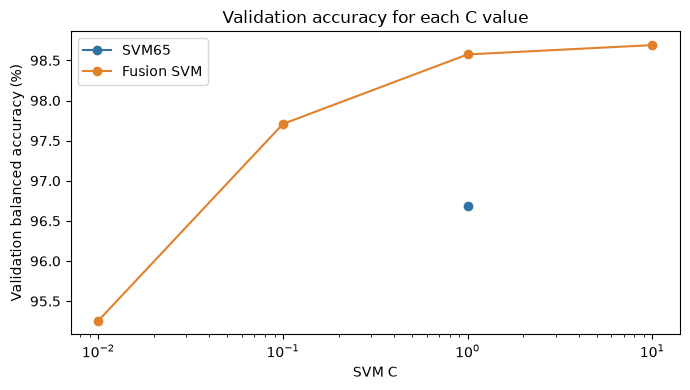

In [6]:
validation_models, validation_predictions = {}, {}
validation_trials, validation_rows = [], []
chosen_c = {}
for name in MODEL_NAMES:
    candidates = [1.] if name == 'SVM65' else FUSION_C_VALUES
    trials = []
    for c_value in candidates:
        started = perf_counter()
        model = make_model(name, train_idx, c_value)
        model.fit(inputs[name][train_idx], labels[train_idx])
        fit_seconds = perf_counter() - started
        frame = prediction_frame(model, name, val_idx, 'validation')
        row = {'model': name, 'C': c_value, 'fit_seconds': fit_seconds, **score_frame(frame)}
        validation_trials.append(row)
        trials.append((row, model, frame))
        print(name, 'C=', c_value, '| validation balanced accuracy:', round(row['balanced_accuracy'], 4), flush=True)
    row, model, frame = max(trials, key=lambda trial: (trial[0]['balanced_accuracy'], trial[0]['macro_f1'], -trial[0]['C']))
    chosen_c[name], validation_models[name], validation_predictions[name] = row['C'], model, frame
    validation_rows.append(row)
validation_table = pd.DataFrame(validation_rows).drop(columns='fit_seconds')
validation_trials = pd.DataFrame(validation_trials)
validation_trials.to_csv(OUTPUT_DIR / 'validation_C_trials.csv', index=False)
validation_table.to_csv(OUTPUT_DIR / 'validation_scores.csv', index=False)
pd.concat(validation_predictions.values()).to_csv(OUTPUT_DIR / 'validation_predictions.csv', index=False)
display(validation_table.round(4))

fig, ax = plt.subplots(figsize=(7, 4))
for name in MODEL_NAMES:
    part = validation_trials.query('model == @name')
    ax.plot(part.C, 100 * part.balanced_accuracy, 'o-', label=name, color=COLORS[name])
ax.set(xscale='log', xlabel='SVM C', ylabel='Validation balanced accuracy (%)', title='Validation accuracy for each C value')
ax.legend()
save_chart(fig, 'validation_C_curve.png')

## 6. Check speaker folds

Use the same three development folds for both models. Keep speakers separate.
Refit scaling, PCA, and SVMs within each fold. Keep features and fusion C fixed.
These folds are exploratory because development labels helped select those settings.

Finished fold 1 SVM65
Finished fold 1 Fusion SVM
Finished fold 2 SVM65
Finished fold 2 Fusion SVM
Finished fold 3 SVM65
Finished fold 3 Fusion SVM


,fold,model,fit_and_score_seconds,balanced_accuracy,macro_f1,sg_recall,non_sg_fpr,roc_auc
0,1,SVM65,6.7019,0.9676,0.9676,0.9768,0.0417,0.9943
1,1,Fusion SVM,6.3741,0.9883,0.9883,0.9887,0.0121,0.9994
2,2,SVM65,6.6924,0.9618,0.9618,0.9806,0.0569,0.9923
3,2,Fusion SVM,5.9164,0.9857,0.9857,0.9917,0.0202,0.9990
4,3,SVM65,6.9884,0.9647,0.9648,0.9756,0.0461,0.9934
5,3,Fusion SVM,6.0987,0.9849,0.9849,0.9878,0.0181,0.9990


,model,balanced_accuracy,macro_f1,sg_recall,non_sg_fpr,roc_auc
0,SVM65,0.9647,0.9647,0.9777,0.0482,0.9932
1,Fusion SVM,0.9863,0.9863,0.9894,0.0168,0.9991


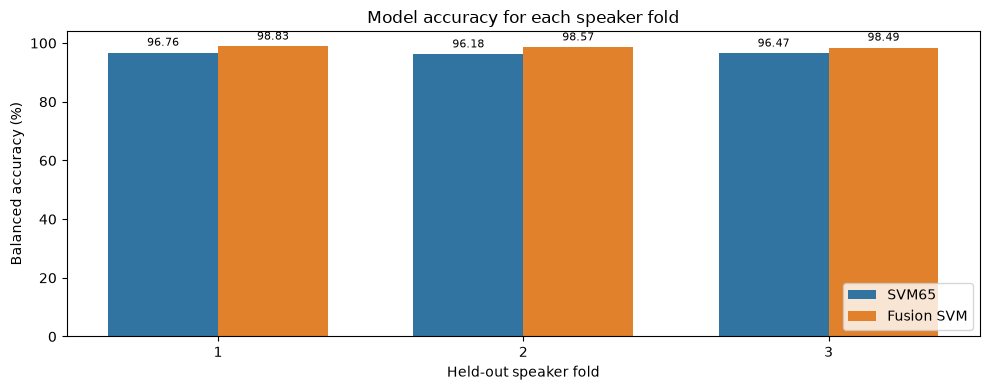

In [7]:
fold_predictions, fold_rows = [], []
if RUN_SPEAKER_FOLDS:
    splitter = StratifiedGroupKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_SEED)
    for fold, (fit_local, held_local) in enumerate(splitter.split(A[development_idx], labels[development_idx], groups[development_idx]), start=1):
        fit_rows, held_rows = development_idx[fit_local], development_idx[held_local]
        assert not set(groups[fit_rows]) & set(groups[held_rows])
        assert not set(np.r_[fit_rows, held_rows]) & set(test_idx)
        assert set(labels[fit_rows]) == set(labels[held_rows]) == {0, 1}
        for name in MODEL_NAMES:
            started = perf_counter()
            model = make_model(name, fit_rows, chosen_c[name])
            model.fit(inputs[name][fit_rows], labels[fit_rows])
            frame = prediction_frame(model, name, held_rows, 'speaker fold', fold=fold)
            fold_predictions.append(frame)
            fold_rows.append({'fold': fold, 'model': name, 'fit_and_score_seconds': perf_counter() - started, **score_frame(frame)})
            print('Finished fold', fold, name, flush=True)
    fold_table = pd.DataFrame(fold_rows)
    fold_table.to_csv(OUTPUT_DIR / 'speaker_fold_scores.csv', index=False)
    fold_frame = pd.concat(fold_predictions, ignore_index=True)
    fold_frame.to_csv(OUTPUT_DIR / 'speaker_fold_predictions.csv', index=False)
    for name in MODEL_NAMES:
        held = fold_frame.loc[fold_frame.model == name]
        assert len(held) == len(development_idx) and held.clip_id.nunique() == len(development_idx)
    combined_fold_table = pd.DataFrame([{'model': name, **score_frame(fold_frame.loc[fold_frame.model == name])} for name in MODEL_NAMES])
    combined_fold_table.to_csv(OUTPUT_DIR / 'combined_fold_scores.csv', index=False)
    display(fold_table.round(4))
    display(combined_fold_table.round(4))
    fig, ax = model_bars(fold_table, 'fold', 'balanced_accuracy',
                         'Model accuracy for each speaker fold')
    ax.set_xlabel('Held-out speaker fold')
    save_chart(fig, 'speaker_folds.png')

## 7. Save the final models

Use E1's saved SVM65 as the final acoustic baseline.
Train fusion on training plus validation with the selected C and fixed 65 features.
Save separate files in this notebook's output folder.

In [8]:
final_models, final_fit_rows = {}, []
for name in MODEL_NAMES:
    started = perf_counter()
    if name == 'SVM65':
        model = e1_saved['model']
    else:
        model = make_model(name, development_idx, chosen_c[name])
        model.fit(inputs[name][development_idx], labels[development_idx])
    seconds = perf_counter() - started
    final_models[name] = model
    final_fit_rows.append({'model': name, 'fit_seconds': seconds})
    filename = 'svm_65.joblib' if name == 'SVM65' else 'fusion_svm.joblib'
    joblib.dump(model, OUTPUT_DIR / filename)
    print('Saved model:', filename, '| fit seconds:', round(seconds, 2), flush=True)
fitted_pca = final_models['Fusion SVM'].named_steps['preprocess'].named_transformers_['whisper'].named_steps['pca']
model_metadata = {
    'dataset_id': dataset_id, 'clips': len(clips),
    'acoustic_feature_count': ACOUSTIC_FEATURE_COUNT, 'feature_names': ACOUSTIC_NAMES, 'feature_columns_in_91': selected_columns,
    'svm65_input': 'raw 65 acoustic values in feature_names order',
    'fusion_input': 'column_stack([raw 65 acoustic values, raw Whisper embedding])',
    'whisper_model': WHISPER_MODEL, 'whisper_revision': WHISPER_REVISION,
    'whisper_width': int(W.shape[1]), 'whisper_pca_dimensions': int(fitted_pca.n_components_),
    'fusion_processed_width': ACOUSTIC_FEATURE_COUNT + int(fitted_pca.n_components_), 'chosen_C': chosen_c,
    'positive_label': 1, 'probability_calibration': False,
    'acoustic_provenance': acoustic_provenance, 'whisper_provenance': whisper_provenance,
    'data_loader_sha256': file_hash(PROJECT_ROOT / 'scripts/cv_utils.py'),
    'e1_source_model_sha256': e1_model_hash, 'e1_study_results_sha256': e1_study_hash,
    'e1_test_reference': e1_test_reference,
    'versions': {'numpy': np.__version__, 'librosa': librosa.__version__, 'sklearn': sklearn.__version__},
}
write_json(OUTPUT_DIR / 'model_metadata.json', model_metadata)
joblib.dump({'models': final_models, 'metadata': model_metadata}, OUTPUT_DIR / 'comparison_models.joblib')
pd.DataFrame(final_fit_rows).to_csv(OUTPUT_DIR / 'final_fit_times.csv', index=False)
assert file_hash(E1_MODEL_PATH) == e1_model_hash
assert file_hash(E1_STUDY_PATH) == e1_study_hash


Saved model: svm_65.joblib | fit seconds: 0.0
Saved model: fusion_svm.joblib | fit seconds: 8.34


## 8. Compare test results

Compare both models on the same test clips at threshold zero.
Report balanced accuracy, errors, and ROC AUC from decision scores.
Estimate fusion's gain with a paired bootstrap of whole speakers within each class.

The test speakers were used before. Keep C, feature counts, and thresholds fixed.
Check that SVM65 reproduces E1's saved balanced accuracy and macro-F1
before interpreting the fusion comparison.


,model,balanced_accuracy,macro_f1,sg_recall,non_sg_fpr,roc_auc,false_positives,false_negatives,errors
0,SVM65,0.9669,0.9668,0.9796,0.0457,0.9939,141,62,203
1,Fusion SVM,0.9868,0.9868,0.9937,0.0201,0.9990,62,19,81


Fusion minus SVM65 balanced accuracy (percentage points): {'gain_points': 1.9890244436633335, 'low_points': 1.4344060775714818, 'high_points': 2.5921893984897078, 'repeats': 2000, 'method': 'paired class-stratified whole-speaker bootstrap; clip-balanced accuracy'}


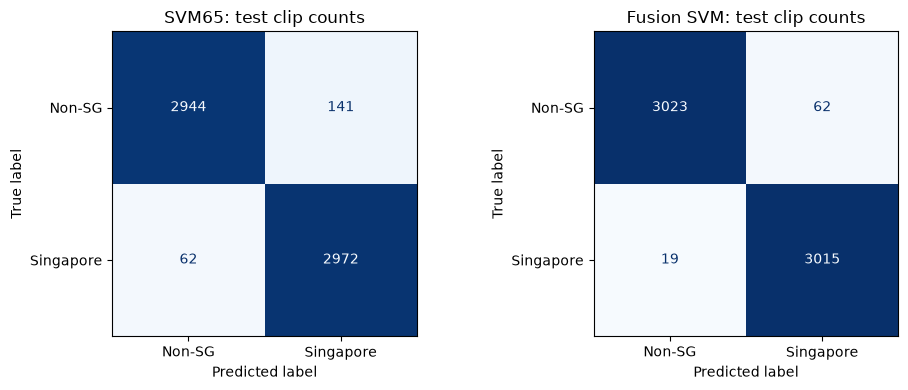

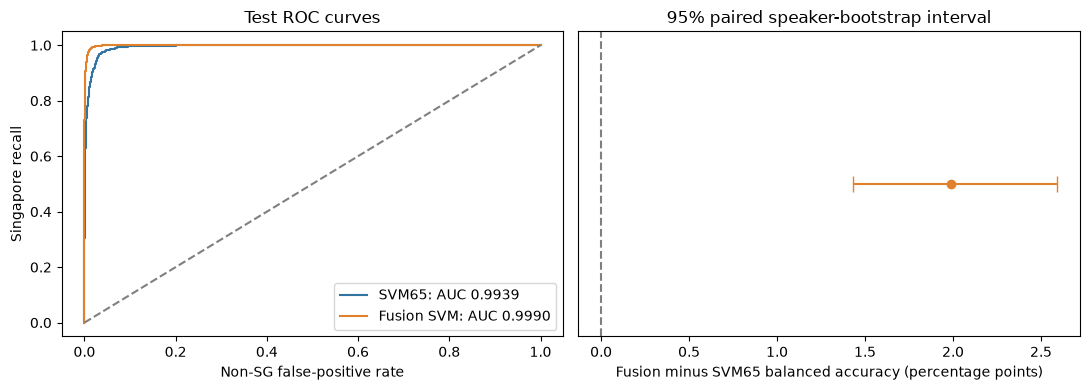

In [9]:
test_predictions, test_confusions = {}, {}
test_rows, timing_rows = [], []
for name in MODEL_NAMES:
    started = perf_counter()
    frame = prediction_frame(final_models[name], name, test_idx, 'test')
    timing_rows.append({'model': name, 'test_predict_and_score_seconds': perf_counter() - started,
                        'input': 'precomputed raw features; excludes audio/Whisper extraction'})
    test_predictions[name] = frame
    cm = confusion_matrix(frame.true_label, frame.prediction, labels=[0, 1])
    test_confusions[name] = cm
    test_rows.append({'model': name, **score_frame(frame), 'false_positives': int(cm[0, 1]),
        'false_negatives': int(cm[1, 0]), 'errors': int(cm[0, 1] + cm[1, 0])})
test_table = pd.DataFrame(test_rows)
baseline_metrics = test_table.loc[test_table.model.eq('SVM65')].iloc[0]
for metric in ('balanced_accuracy', 'macro_f1'):
    if not np.isclose(baseline_metrics[metric], e1_test_reference[metric], rtol=0, atol=1e-12):
        raise ValueError(f'SVM65 {metric} differs from the completed E1 test result.')
test_table.to_csv(OUTPUT_DIR / 'test_scores.csv', index=False)
pd.concat(test_predictions.values()).to_csv(OUTPUT_DIR / 'test_predictions.csv', index=False)
pd.DataFrame(timing_rows).to_csv(OUTPUT_DIR / 'test_prediction_times.csv', index=False)
paired_gain = paired_speaker_interval(test_predictions['Fusion SVM'], test_predictions['SVM65'])
write_json(OUTPUT_DIR / 'paired_test_gain.json', paired_gain)
display(test_table.round(4))
print('Fusion minus SVM65 balanced accuracy (percentage points):', paired_gain)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
maximum = max(cm.max() for cm in test_confusions.values())
for ax, name in zip(axes, MODEL_NAMES):
    ConfusionMatrixDisplay(test_confusions[name], display_labels=['Non-SG', 'Singapore']).plot(
        ax=ax, colorbar=False, cmap='Blues', im_kw={'vmin': 0, 'vmax': maximum})
    ax.set_title(name + ': test clip counts')
save_chart(fig, 'test_confusion_matrices.png')

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name in MODEL_NAMES:
    f = test_predictions[name]
    fpr, tpr, _ = roc_curve(f.true_label, f.decision_score)
    axes[0].plot(fpr, tpr, label=f"{name}: AUC {roc_auc_score(f.true_label, f.decision_score):.4f}", color=COLORS[name])
axes[0].plot([0, 1], [0, 1], '--', color='gray')
axes[0].set(xlabel='Non-SG false-positive rate', ylabel='Singapore recall', title='Test ROC curves')
axes[0].legend()
axes[1].errorbar(paired_gain['gain_points'], 0,
    xerr=[[paired_gain['gain_points'] - paired_gain['low_points']], [paired_gain['high_points'] - paired_gain['gain_points']]],
    fmt='o', capsize=6, color=COLORS['Fusion SVM'])
axes[1].axvline(0, color='gray', linestyle='--')
axes[1].set(yticks=[], xlabel='Fusion minus SVM65 balanced accuracy (percentage points)', title='95% paired speaker-bootstrap interval')
save_chart(fig, 'test_roc_and_paired_gain.png')

## 9. Compare stages and scoring weights

Show training, validation, speaker-fold, and test scores.
These stages use different fitting data.

Compare equal clip weights with equal speaker weights.
Speaker weights change only the scores, not the fitted models.

,stage,model,weighting,balanced_accuracy,macro_f1,sg_recall,non_sg_fpr,roc_auc
0,validation,SVM65,Equal clips,0.9669,0.9668,0.9785,0.0447,0.9927
1,validation,SVM65,Equal speakers,0.9692,0.9287,0.9771,0.0387,0.9943
2,test,SVM65,Equal clips,0.9669,0.9668,0.9796,0.0457,0.9939
3,test,SVM65,Equal speakers,0.9722,0.9390,0.9787,0.0344,0.9954
4,validation,Fusion SVM,Equal clips,0.9869,0.9869,0.9937,0.0199,0.9992
5,validation,Fusion SVM,Equal speakers,0.9905,0.9770,0.9928,0.0117,0.9994
6,test,Fusion SVM,Equal clips,0.9868,0.9868,0.9937,0.0201,0.9990
7,test,Fusion SVM,Equal speakers,0.9892,0.9761,0.9911,0.0127,0.9992


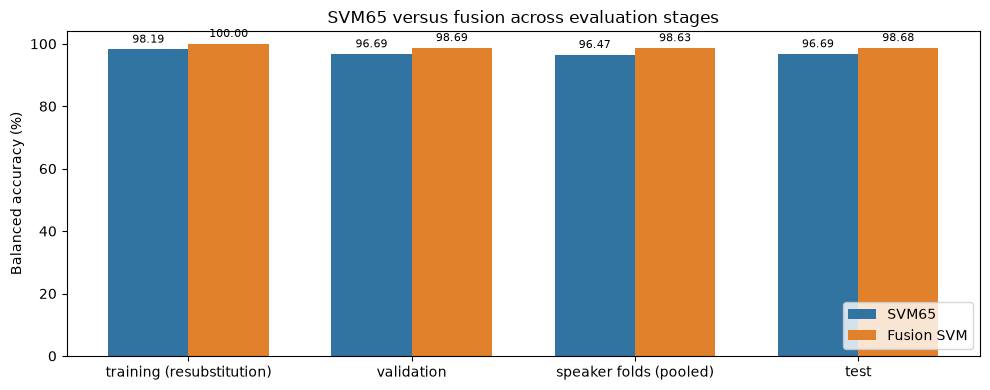

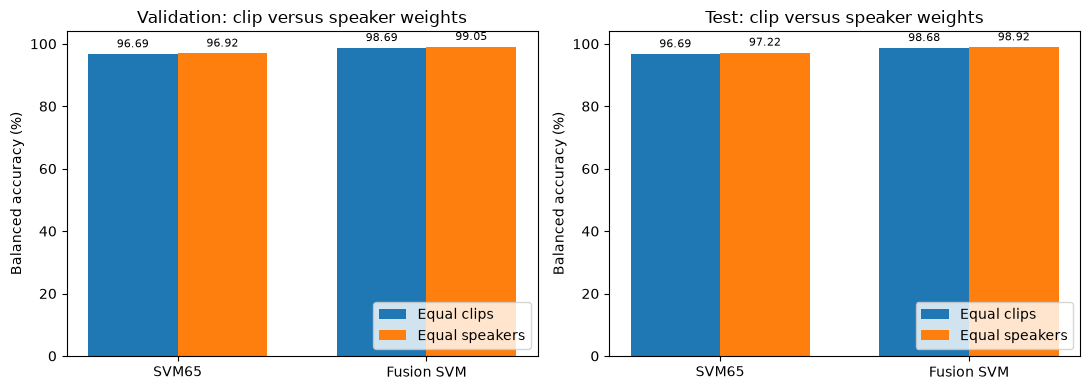

In [10]:
stage_rows, weight_rows = [], []
for name in MODEL_NAMES:
    train_frame = prediction_frame(validation_models[name], name, train_idx, 'training (resubstitution)')
    for stage, frame in [('training (resubstitution)', train_frame), ('validation', validation_predictions[name]), ('test', test_predictions[name])]:
        scores = score_frame(frame)
        stage_rows.append({'stage': stage, 'model': name, **scores})
        if stage != 'training (resubstitution)':
            weight_rows.append({'stage': stage, 'model': name, 'weighting': 'Equal clips', **scores})
            weight_rows.append({'stage': stage, 'model': name, 'weighting': 'Equal speakers',
                                **score_frame(frame, speaker_weighted=True)})
    if RUN_SPEAKER_FOLDS:
        stage_rows.append({'stage': 'speaker folds (pooled)', 'model': name,
            **score_frame(fold_frame.loc[fold_frame.model == name])})
stage_table = pd.DataFrame(stage_rows)
weight_table = pd.DataFrame(weight_rows)
stage_table.to_csv(OUTPUT_DIR / 'stage_comparison.csv', index=False)
weight_table.to_csv(OUTPUT_DIR / 'speaker_weight_comparison.csv', index=False)
display(weight_table.round(4))

stages = ['training (resubstitution)', 'validation'] + (['speaker folds (pooled)'] if RUN_SPEAKER_FOLDS else []) + ['test']
fig, ax = model_bars(stage_table, 'stage', 'balanced_accuracy',
                     'SVM65 versus fusion across evaluation stages', order=stages)
save_chart(fig, 'stage_comparison.png')

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, stage in zip(axes, ['validation', 'test']):
    for offset, weighting in zip([-0.18, 0.18], ['Equal clips', 'Equal speakers']):
        values = weight_table.query('stage == @stage and weighting == @weighting').set_index('model').loc[list(MODEL_NAMES), 'balanced_accuracy'].to_numpy() * 100
        bars = ax.bar(np.arange(2) + offset, values, 0.36, label=weighting)
        ax.bar_label(bars, fmt='%.2f', padding=3, fontsize=8)
    ax.set(xticks=[0, 1], xticklabels=list(MODEL_NAMES), ylim=(0, 104), ylabel='Balanced accuracy (%)', title=stage.title() + ': clip versus speaker weights')
    ax.legend(loc='lower right')
save_chart(fig, 'speaker_weight_comparison.png')

## 10. Check each source

Report source accuracy, false positives, and false negatives.
Singapore is class 1. MNSC errors are false negatives; other source errors are false positives.
Sources contain one class, so source and accent effects cannot be separated.

,model,source,clips,speakers,sg_clips,accuracy,false_positives,false_negatives,total_errors
0,SVM65,common_voice,2913,1241,0,0.9753,72,0,72
1,SVM65,mnsc,3034,215,3034,0.9796,0,62,62
2,SVM65,speech_accent_archive,50,8,0,0.6000,20,0,20
3,SVM65,speechocean762,122,18,0,0.5984,49,0,49
4,Fusion SVM,common_voice,2913,1241,0,0.9883,34,0,34
5,Fusion SVM,mnsc,3034,215,3034,0.9937,0,19,19
6,Fusion SVM,speech_accent_archive,50,8,0,0.9200,4,0,4
7,Fusion SVM,speechocean762,122,18,0,0.8033,24,0,24


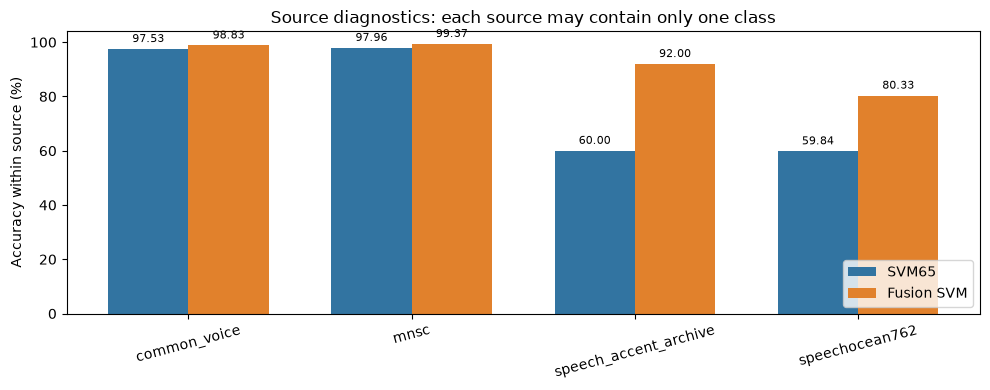

In [11]:
source_rows = []
for name in MODEL_NAMES:
    for source, frame in test_predictions[name].groupby('source'):
        false_positives = int((frame.true_label.eq(0) & frame.prediction.eq(1)).sum())
        false_negatives = int((frame.true_label.eq(1) & frame.prediction.eq(0)).sum())
        source_rows.append({'model': name, 'source': source, 'clips': len(frame),
            'speakers': frame.speaker_group.nunique(), 'sg_clips': int(frame.true_label.sum()),
            'accuracy': float(frame.prediction.eq(frame.true_label).mean()),
            'false_positives': false_positives, 'false_negatives': false_negatives,
            'total_errors': false_positives + false_negatives})
source_table = pd.DataFrame(source_rows)
source_table.to_csv(OUTPUT_DIR / 'test_source_diagnostics.csv', index=False)
display(source_table.round(4))
fig, ax = model_bars(source_table.sort_values('source'), 'source', 'accuracy',
                     'Source diagnostics: each source may contain only one class')
ax.set_ylabel('Accuracy within source (%)')
ax.tick_params(axis='x', labelrotation=15)
save_chart(fig, 'source_diagnostics.png')